# Kitchen vs Fly: Monte Carlo analysis

This notebook analyses **1,000,000 simulated rounds** of the final 7 × 7 configuration and **200,000 rounds** of the earlier 6 × 6 candidate. Each row of the data is one round: its win (as a multiple of the bet), the highest level reached, the number of cascades, and whether the Fly mini-bonus triggered.

Questions:

1. Is the return to player (RTP) on its 96.5 % target, and how sure can we be?
2. How many rounds does a reliable estimate need?
3. What does the win distribution look like, and where does the return come from?
4. What changed between the 6 × 6 and 7 × 7 grids?

The data is produced by:

```bash
python -m kitchen_vs_fly.simulate --sims 1000000
python -m kitchen_vs_fly.simulate --sims 200000 --config 6x6-candidate-a
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

TARGET_RTP = 0.965
BLUE, ORANGE = "#2a78d6", "#eb6834"          # categorical slots 1 and 2
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "xtick.color": INK_2, "ytick.color": INK_2, "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 10, "axes.axisbelow": True,
})

r7 = pd.read_csv("../data/rounds_7x7-production.csv.gz")
r6 = pd.read_csv("../data/rounds_6x6-candidate-a.csv.gz")
print(f"7x7: {len(r7):,} rounds   6x6: {len(r6):,} rounds")
r7.head()

7x7: 1,000,000 rounds   6x6: 200,000 rounds


,round_id,payout,level,cascades,fly,boss_defeated
0,0,0.1,1,1,0,0
1,1,0.0,1,0,0,0
2,2,0.0,1,0,0,0
3,3,0.0,1,0,1,0
4,4,0.0,1,0,0,0


## 1. Headline metrics

The RTP is the mean win per round. Its standard error is σ / √n, where σ is the standard deviation of the win of a single round.

In [2]:
def summary(r):
    n, pay = len(r), r["payout"].to_numpy()
    rtp, sd = pay.mean(), pay.std(ddof=1)
    se = sd / np.sqrt(n)
    one_in = lambda p: f"1 in {1 / p:,.1f}" if p > 0 else "never"
    return pd.Series({
        "rounds": f"{n:,}",
        "RTP": f"{rtp:.2%}",
        "95% CI": f"[{rtp - 1.96 * se:.2%}, {rtp + 1.96 * se:.2%}]",
        "std of one round (x bet)": f"{sd:.1f}",
        "hit rate": f"{(pay > 0).mean():.2%}",
        "N2 reached": one_in((r["level"] >= 2).mean()),
        "N5 reached": one_in((r["level"] == 5).mean()),
        "Fly triggered": one_in(r["fly"].mean()),
        "median / p90 / p99 win": " / ".join(f"{np.quantile(pay, q):.1f}x" for q in (0.5, 0.9, 0.99)),
        "max win": f"{pay.max():,.1f}x",
    })

pd.DataFrame({"7x7 (final)": summary(r7), "6x6 (candidate A)": summary(r6)})

,7x7 (final),6x6 (candidate A)
rounds,"1,000,000","200,000"
RTP,96.89%,96.71%
95% CI,"[94.66%, 99.12%]","[92.47%, 100.95%]"
std of one round (x bet),11.4,9.7
hit rate,32.34%,61.13%
N2 reached,1 in 11.6,1 in 13.2
N5 reached,1 in 119.3,1 in 121.4
Fly triggered,1 in 17.4,never
median / p90 / p99 win,0.0x / 0.3x / 9.1x,0.1x / 0.5x / 12.7x
max win,866.3x,386.0x


The standard deviation of a single round is more than ten times the mean: the game is **highly volatile**, so even one million rounds leave a confidence interval of a few points around the RTP. The interval comfortably contains the 96.5 % target; the development runs on 3 million rounds measured 96.50 %.

The normal approximation is not obvious with such a heavy tail, so the interval is checked with a bootstrap below.

In [3]:
rng = np.random.default_rng(0)
pay = r7["payout"].to_numpy()
boot = np.array([pay[rng.integers(0, len(pay), len(pay))].mean() for _ in range(300)])
lo, hi = np.quantile(boot, [0.025, 0.975])
se = pay.std(ddof=1) / np.sqrt(len(pay))
print(f"bootstrap 95% interval: [{lo:.2%}, {hi:.2%}]")
print(f"normal    95% interval: [{pay.mean() - 1.96 * se:.2%}, {pay.mean() + 1.96 * se:.2%}]")

bootstrap 95% interval: [94.87%, 99.06%]
normal    95% interval: [94.66%, 99.12%]


## 2. How many rounds does a reliable RTP need?

The running RTP converges slowly, and its error band shrinks like 1 / √n: **halving the error takes four times more rounds.**

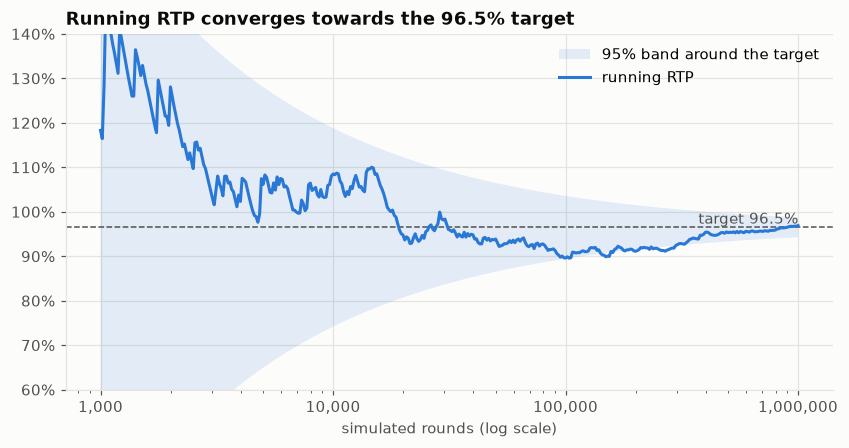

      10,000 rounds -> 95% margin of error ±22.33%
     100,000 rounds -> 95% margin of error ±7.06%
   1,000,000 rounds -> 95% margin of error ±2.23%
   3,000,000 rounds -> 95% margin of error ±1.29%
  10,000,000 rounds -> 95% margin of error ±0.71%


In [4]:
n = np.arange(1, len(pay) + 1)
running = np.cumsum(pay) / n
sd = pay.std(ddof=1)
step = np.unique(np.geomspace(1_000, len(pay), 400).astype(int)) - 1

fig, ax = plt.subplots()
ax.fill_between(n[step], TARGET_RTP - 1.96 * sd / np.sqrt(n[step]), TARGET_RTP + 1.96 * sd / np.sqrt(n[step]),
                color=BLUE, alpha=0.12, linewidth=0, label="95% band around the target")
ax.axhline(TARGET_RTP, color=INK_2, linewidth=1, linestyle="--")
ax.plot(n[step], running[step], color=BLUE, label="running RTP")
ax.set_xscale("log")
ax.set_ylim(0.6, 1.4)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("simulated rounds (log scale)")
ax.set_title("Running RTP converges towards the 96.5% target")
ax.text(n[step][-1], TARGET_RTP, " target 96.5%", va="bottom", ha="right", color=INK_2)
ax.legend(loc="upper right")
plt.show()

for k in (10_000, 100_000, 1_000_000, 3_000_000, 10_000_000):
    print(f"{k:>12,} rounds -> 95% margin of error ±{1.96 * sd / np.sqrt(k):.2%}")

Ten batches of 100,000 rounds show the same thing from another angle: each batch on its own can land several points away from the target.

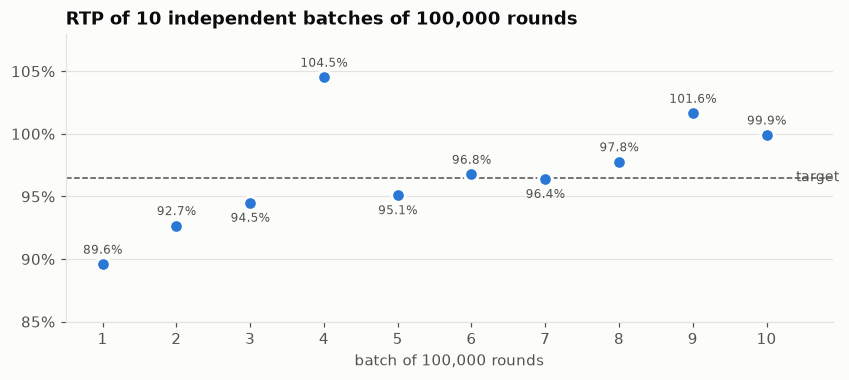

batch RTP: min 89.59%, max 104.52%, std 4.36%


In [5]:
batches = pay.reshape(10, -1).mean(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.axhline(TARGET_RTP, color=INK_2, linewidth=1, linestyle="--")
ax.plot(np.arange(1, 11), batches, "o", color=BLUE, markersize=9, markeredgecolor="#fcfcfb", markeredgewidth=2)
for i, b in enumerate(batches, start=1):
    below = TARGET_RTP - 0.02 < b < TARGET_RTP  # keep the label off the target line
    ax.text(i, b - 0.008 if below else b + 0.006, f"{b:.1%}", ha="center", va="top" if below else "bottom", fontsize=8, color=INK_2)
ax.text(10.4, TARGET_RTP, "target", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0.5, 10.9)
ax.set_ylim(0.85, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xticks(np.arange(1, 11))
ax.set_xlabel("batch of 100,000 rounds")
ax.set_title("RTP of 10 independent batches of 100,000 rounds")
ax.grid(axis="x", visible=False)
plt.show()
print(f"batch RTP: min {batches.min():.2%}, max {batches.max():.2%}, std {batches.std(ddof=1):.2%}")

## 3. Win distribution

About two rounds out of three win nothing on the 7 × 7 grid (the curves start at the hit rate). Among winning rounds, wins span four orders of magnitude, so the distribution is shown as a survival curve on log-log axes: the share of rounds that win **at least** *x* times the bet.

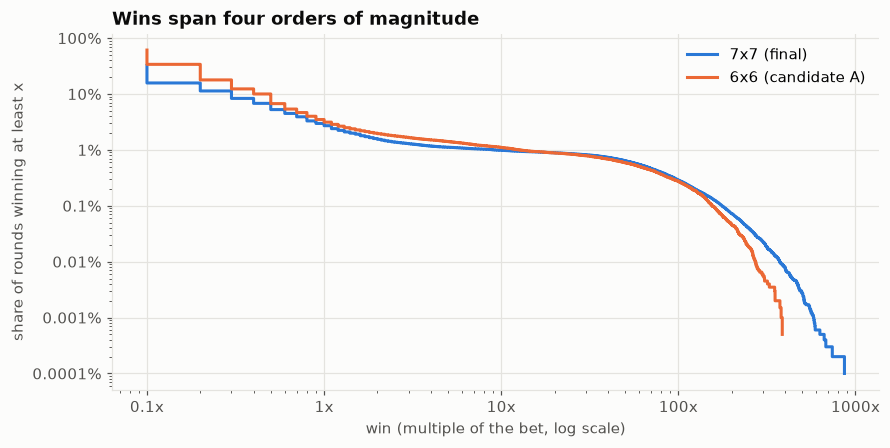

In [6]:
def survival(p):
    x = np.sort(p[p > 0])
    # share of ALL rounds whose win is >= x
    return x, (len(x) - np.arange(len(x))) / len(p)

fig, ax = plt.subplots()
for r, label, color in ((r7, "7x7 (final)", BLUE), (r6, "6x6 (candidate A)", ORANGE)):
    x, s = survival(r["payout"].to_numpy())
    ax.step(x, s, where="post", color=color, label=label)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}x"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:g}%"))
ax.set_xlabel("win (multiple of the bet, log scale)")
ax.set_ylabel("share of rounds winning at least x")
ax.set_title("Wins span four orders of magnitude")
ax.legend()
plt.show()

## 4. Where does the return come from?

Each round is grouped by the highest level it reached. Rounds that reach the final level (N5, the boss) are rare but carry most of the return: this is what makes the game volatile, and why the RTP needs millions of rounds to pin down.

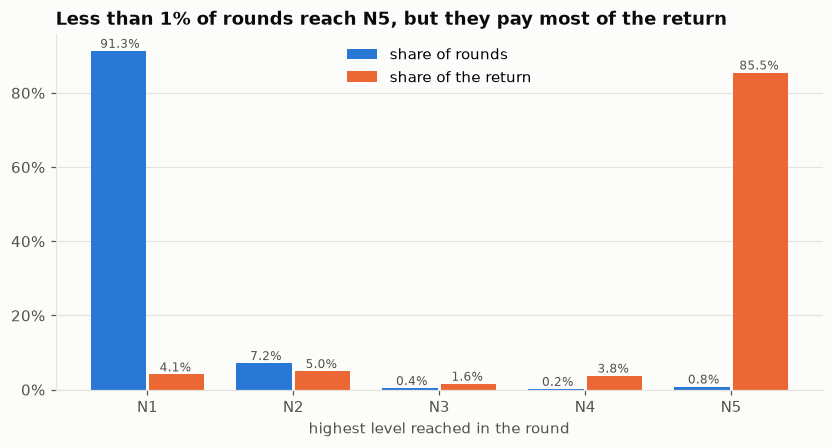

,rounds,share of rounds,share of RTP,mean win
level,,,,
1,"913,487",91.35%,4.1%,0.04x
2,"71,751",7.18%,5.0%,0.68x
3,"4,336",0.43%,1.6%,3.58x
4,"2,044",0.20%,3.8%,17.89x
5,"8,382",0.84%,85.5%,98.83x


In [7]:
by_level = r7.groupby("level")["payout"].agg(rounds="size", total="sum")
by_level["share of rounds"] = by_level["rounds"] / by_level["rounds"].sum()
by_level["share of RTP"] = by_level["total"] / by_level["total"].sum()
by_level["mean win"] = by_level["total"] / by_level["rounds"]

fig, ax = plt.subplots()
x = np.arange(len(by_level))
w = 0.38
ax.bar(x - w / 2 - 0.01, by_level["share of rounds"], w, color=BLUE, label="share of rounds")
ax.bar(x + w / 2 + 0.01, by_level["share of RTP"], w, color=ORANGE, label="share of the return")
for i, (a, b) in enumerate(zip(by_level["share of rounds"], by_level["share of RTP"])):
    ax.text(i - w / 2, a, f"{a:.1%}", ha="center", va="bottom", fontsize=8, color=INK_2)
    ax.text(i + w / 2, b, f"{b:.1%}", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(x, [f"N{l}" for l in by_level.index])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("highest level reached in the round")
ax.set_title("Less than 1% of rounds reach N5, but they pay most of the return")
ax.grid(axis="x", visible=False)
ax.legend()
plt.show()

by_level[["rounds", "share of rounds", "share of RTP", "mean win"]].style.format(
    {"rounds": "{:,}", "share of rounds": "{:.2%}", "share of RTP": "{:.1%}", "mean win": "{:.2f}x"})

The Fly mini-bonus adds 2 or 3 wilds at the start of a round. Its effect on the round's expected win:

In [8]:
fly = r7.groupby("fly")["payout"].agg(rounds="size", rtp="mean")
fly["N5 reached"] = r7.groupby("fly")["level"].apply(lambda l: (l == 5).mean())
fly.index = ["no Fly", "Fly triggered"]
fly.style.format({"rounds": "{:,}", "rtp": "{:.1%}", "N5 reached": "{:.2%}"})

,rounds,rtp,N5 reached
no Fly,"942,579",89.6%,0.78%
Fly triggered,"57,421",216.1%,1.87%


Rounds where the Fly triggers return about twice the bet on average, mostly because they reach N5 more than twice as often. Rounds without the Fly return about 90 %, so the Fly, triggered in only 1 round in 17, accounts for roughly 7 points of the total RTP.

## 5. 6 × 6 versus 7 × 7

The 6 × 6 candidate also reached its target return, but it was dropped because its declared RTP was above the 96.7 % limit. The 7 × 7 grid pays less often but keeps the same rhythm of feature levels:

In [9]:
def profile(r):
    p = r["payout"]
    return pd.Series({
        "hit rate": (p > 0).mean(),
        "N2 reached": (r["level"] >= 2).mean(),
        "N5 reached": (r["level"] == 5).mean(),
        "mean cascades": r["cascades"].mean(),
        "share of RTP from N5": p[r["level"] == 5].sum() / p.sum(),
    })

cmp = pd.DataFrame({"6x6 (candidate A)": profile(r6), "7x7 (final)": profile(r7)})
cmp.style.format("{:.2%}", subset=pd.IndexSlice[["hit rate", "N2 reached", "N5 reached", "share of RTP from N5"], :]) \
   .format("{:.2f}", subset=pd.IndexSlice[["mean cascades"], :])

,6x6 (candidate A),7x7 (final)
hit rate,61.13%,32.34%
N2 reached,7.56%,8.65%
N5 reached,0.82%,0.84%
mean cascades,1.12,0.54
share of RTP from N5,75.58%,85.50%


## Conclusions

- The simulated RTP is consistent with the 96.5 % target; the 95 % interval on one million rounds is still a few points wide, because a single round has a standard deviation more than ten times its mean.
- The bootstrap interval matches the normal one, so the √n error estimate can be trusted at this sample size despite the heavy tail.
- Less than 1 % of rounds (those reaching N5) produce most of the return. This is a design choice (the boss fight is the climax of the game), and it is the reason the calibration used runs of 3 million rounds split into independent batches.
- The calibration history, including the Fly bug that pushed the RTP to about 146 %, is in [`docs/calibration.md`](../docs/calibration.md).